In [212]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [213]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

data = pd.read_csv(url)

data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [214]:
df = data.copy()

In [215]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [216]:
print(df.shape)
print(df.info())

(20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB
None


In [217]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [218]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [280]:
data.duplicated().sum()

np.int64(0)

In [221]:
df['median_house_value'].describe()

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64

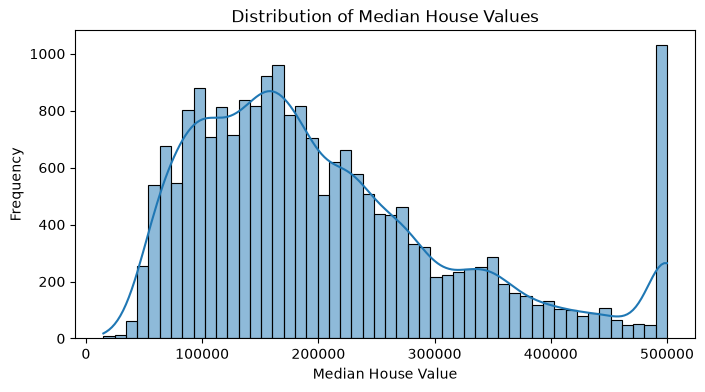

In [222]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(df['median_house_value'], bins=50, kde=True)
plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

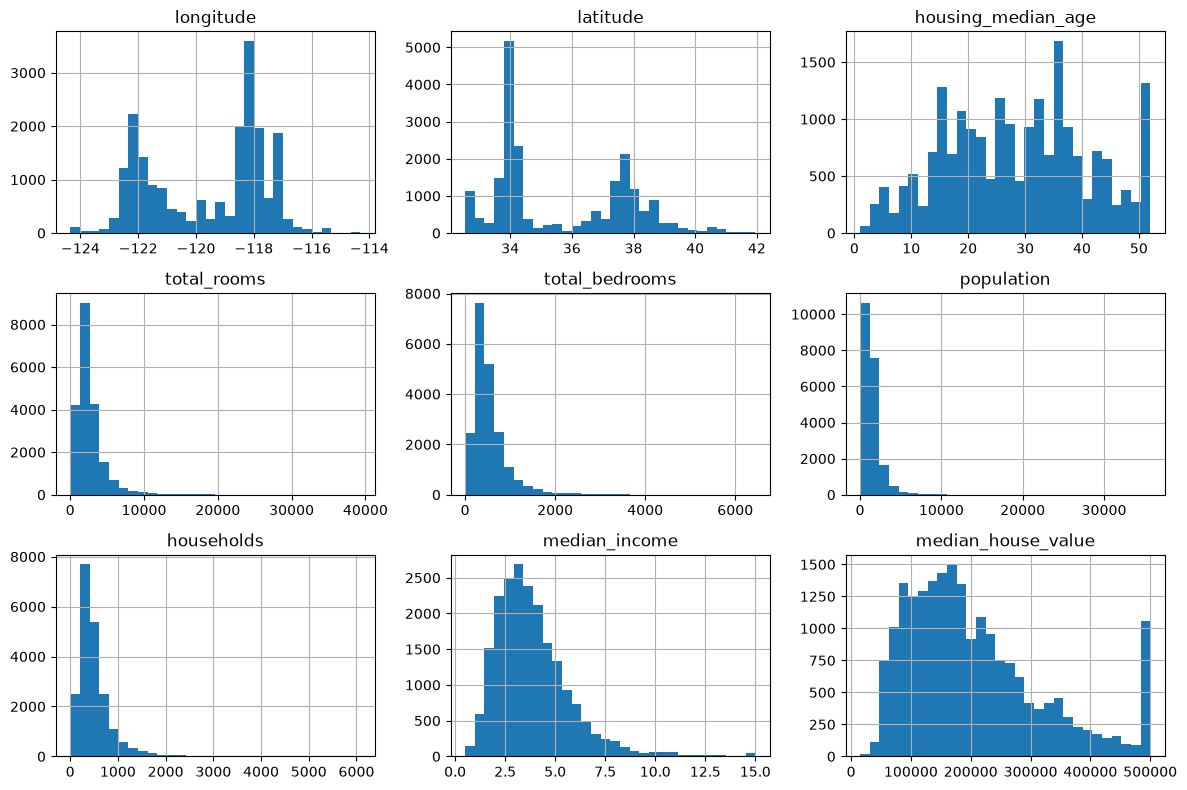

In [223]:
df.hist(figsize=(12,8), bins=30)
plt.tight_layout()
plt.show()

## Correlation analysis

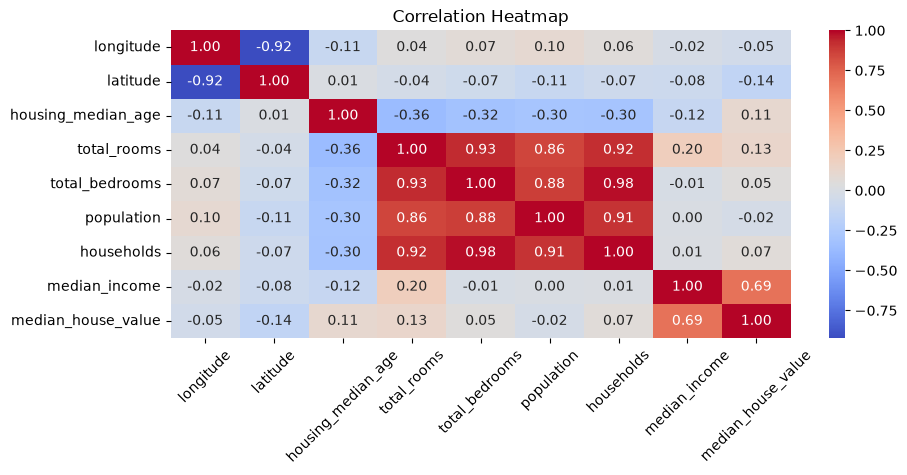

In [224]:
numerical_df = df.select_dtypes(include='number')

plt.figure(figsize=(10,4))
sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.xticks(rotation=45)
plt.show()

## Feature Engineering

In [225]:
df['rooms_per_household'] = (
    df['total_rooms'] / df['households']
)

In [226]:
df['bedrooms_per_room'] = (
    df['total_bedrooms'] / df['total_rooms']
)

In [227]:
df['population_per_household'] = (
    df['population'] / df['households']
)

In [228]:
df['income_rooms_interaction'] = (
    df['median_income'] * df['rooms_per_household']
)

In [229]:
df[['rooms_per_household',
    'bedrooms_per_room',
    'population_per_household']].head()

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


In [230]:
df.shape

(20640, 14)

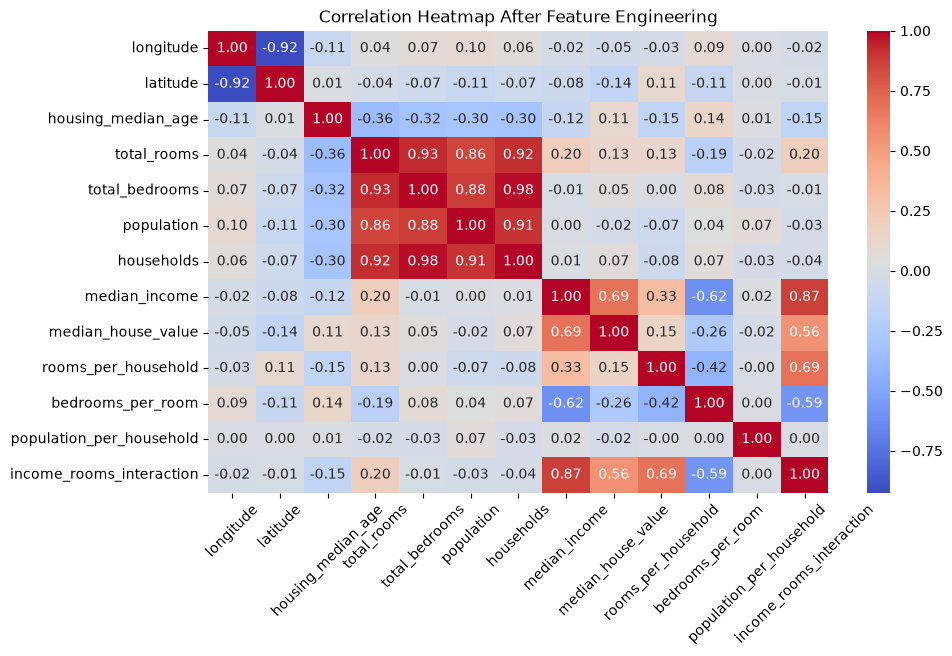

In [231]:
numerical_df = df.select_dtypes(include='number')

plt.figure(figsize=(10, 6))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap After Feature Engineering')
plt.xticks(rotation=45)
plt.show()

### Multicollinearity Analysis using VIF

In [232]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [233]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [234]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

# Select numerical features
vif_data = df.select_dtypes(include=['int64', 'float64']).drop(
    columns=['median_house_value']
).copy()

# Handle missing and infinite values
vif_data = vif_data.replace([np.inf, -np.inf], np.nan)
vif_data = vif_data.fillna(vif_data.median())

# Remove constant columns
vif_data = vif_data.loc[:, vif_data.nunique() > 1]

# Standardize features
scaler = StandardScaler()
vif_scaled = scaler.fit_transform(vif_data)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = vif_data.columns
vif['VIF'] = [
    variance_inflation_factor(vif_scaled, i)
    for i in range(vif_scaled.shape[1])
]

print(vif.sort_values(by='VIF', ascending=False))

                     Feature        VIF
6                 households  34.065816
4             total_bedrooms  33.866869
11  income_rooms_interaction  18.210530
3                total_rooms  17.258460
7              median_income  13.052837
1                   latitude   9.501681
0                  longitude   9.173960
5                 population   6.707204
8        rooms_per_household   5.406906
9          bedrooms_per_room   2.745659
2         housing_median_age   1.261982
10  population_per_household   1.066125


## Separate Features (X) and Target (y)

In [235]:
X = df.drop('median_house_value', axis=1)

y = df['median_house_value']

In [236]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 13)
y shape: (20640,)


## Train-Test Split

In [237]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [238]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 13)
X_test: (4128, 13)
y_train: (16512,)
y_test: (4128,)


## Identify Numerical and Categorical Columns

In [239]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object', 'str']
).columns

In [240]:
print("Numerical Features:", list(numerical_features))
print("Categorical Features:", list(categorical_features))

Numerical Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_rooms_interaction']
Categorical Features: ['ocean_proximity']


## Import preprocessing libraries

In [241]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [242]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [243]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [244]:
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [245]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [246]:
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (16512, 17)
Testing data shape: (4128, 17)


## Import regression models and evaluation metrics

In [247]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [248]:
ols_model = LinearRegression()

ols_model.fit(X_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](17,)","[-55498.43,-55796.58, 14260.78,...,111502.7 ,-24210.5 ,-15481.44]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.37e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,17
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](17,)","[254.4 ,218.21,181.39,..., 13.4 , 2.23, 0. ]"


In [249]:
y_pred_ols = ols_model.predict(X_test_processed)

In [250]:
print("OLS Regression Results")

print("RMSE:", mean_squared_error(y_test, y_pred_ols) ** 0.5)

print("MAE:", mean_absolute_error(y_test, y_pred_ols))

print("R2 Score:", r2_score(y_test, y_pred_ols))

OLS Regression Results
RMSE: 68917.31673236135
MAE: 49709.53953194077
R2 Score: 0.6375485345067997


## Train Ridge Regression (L2 Regularization)

In [251]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_processed, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [252]:
y_pred_ridge = ridge_model.predict(X_test_processed)

In [253]:
print("Ridge Regression Results")

print("RMSE:", mean_squared_error(y_test, y_pred_ridge) ** 0.5)

print("MAE:", mean_absolute_error(y_test, y_pred_ridge))

print("R2 Score:", r2_score(y_test, y_pred_ridge))

Ridge Regression Results
RMSE: 68925.95724807172
MAE: 49715.84081394086
R2 Score: 0.6374576440295385


## Train Lasso Regression (L1 Regularization)

In [254]:
lasso_model = Lasso(alpha=1.0, max_iter=10000)

lasso_model.fit(X_train_processed, y_train)

,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [255]:
y_pred_lasso = lasso_model.predict(X_test_processed)

In [256]:
print("Lasso Regression Results")

print("RMSE:", mean_squared_error(y_test, y_pred_lasso) ** 0.5)

print("MAE:", mean_absolute_error(y_test, y_pred_lasso))

print("R2 Score:", r2_score(y_test, y_pred_lasso))

Lasso Regression Results
RMSE: 68918.67580483857
MAE: 49710.271514983804
R2 Score: 0.637534239038214


## Compare all three models

In [257]:
import pandas as pd

results = pd.DataFrame({
    'Model': ['OLS', 'Ridge', 'Lasso'],
    'RMSE': [
        mean_squared_error(y_test, y_pred_ols) ** 0.5,
        mean_squared_error(y_test, y_pred_ridge) ** 0.5,
        mean_squared_error(y_test, y_pred_lasso) ** 0.5
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_ols),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_lasso)
    ],
    'R2 Score': [
        r2_score(y_test, y_pred_ols),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso)
    ]
})

results

,Model,RMSE,MAE,R2 Score
0,OLS,68917.316732,49709.539532,0.637549
1,Ridge,68925.957248,49715.840814,0.637458
2,Lasso,68918.675805,49710.271515,0.637534


In [258]:
from sklearn.model_selection import GridSearchCV

In [259]:
ridge_params = {
    'alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

In [260]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

ridge_grid = GridSearchCV(
    ridge_pipeline,
    {'model__alpha': ridge_params['alpha']},
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

In [261]:
ridge_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information prin

In [262]:
print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", (-ridge_grid.best_score_) ** 0.5)

Best Ridge Alpha: {'model__alpha': 1}
Best Ridge CV RMSE: 67777.5733690034


In [263]:
lasso_params = {
    'alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

In [264]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(max_iter=10000))
])

lasso_grid = GridSearchCV(
    lasso_pipeline,
    {'model__alpha': lasso_params['alpha']},
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

In [265]:
lasso_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=10000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printe

In [266]:
print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Lasso CV RMSE:", (-lasso_grid.best_score_) ** 0.5)

Best Lasso Alpha: {'model__alpha': 1}
Best Lasso CV RMSE: 67778.90411908389


In [267]:
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

In [269]:
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

y_pred_ridge_tuned = best_ridge.predict(X_test)
y_pred_lasso_tuned = best_lasso.predict(X_test)

In [270]:
print("Tuned Ridge Results")
print("RMSE:", mean_squared_error(y_test, y_pred_ridge_tuned) ** 0.5)
print("MAE:", mean_absolute_error(y_test, y_pred_ridge_tuned))
print("R2:", r2_score(y_test, y_pred_ridge_tuned))

print("\nTuned Lasso Results")
print("RMSE:", mean_squared_error(y_test, y_pred_lasso_tuned) ** 0.5)
print("MAE:", mean_absolute_error(y_test, y_pred_lasso_tuned))
print("R2:", r2_score(y_test, y_pred_lasso_tuned))

Tuned Ridge Results
RMSE: 68925.95724807172
MAE: 49715.84081394086
R2: 0.6374576440295385

Tuned Lasso Results
RMSE: 68918.67580483857
MAE: 49710.271514983804
R2: 0.637534239038214


## Compare tuned models

In [271]:
tuned_results = pd.DataFrame({
    'Model': ['OLS', 'Tuned Ridge', 'Tuned Lasso'],
    'RMSE': [
        mean_squared_error(y_test, y_pred_ols) ** 0.5,
        mean_squared_error(y_test, y_pred_ridge_tuned) ** 0.5,
        mean_squared_error(y_test, y_pred_lasso_tuned) ** 0.5
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_ols),
        mean_absolute_error(y_test, y_pred_ridge_tuned),
        mean_absolute_error(y_test, y_pred_lasso_tuned)
    ],
    'R2 Score': [
        r2_score(y_test, y_pred_ols),
        r2_score(y_test, y_pred_ridge_tuned),
        r2_score(y_test, y_pred_lasso_tuned)
    ]
})

tuned_results

,Model,RMSE,MAE,R2 Score
0,OLS,68917.316732,49709.539532,0.637549
1,Tuned Ridge,68925.957248,49715.840814,0.637458
2,Tuned Lasso,68918.675805,49710.271515,0.637534


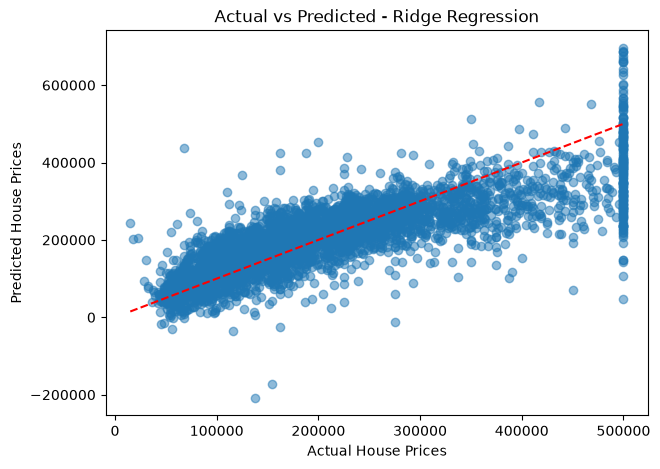

In [272]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_ridge_tuned, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Actual vs Predicted - Ridge Regression')

plt.show()

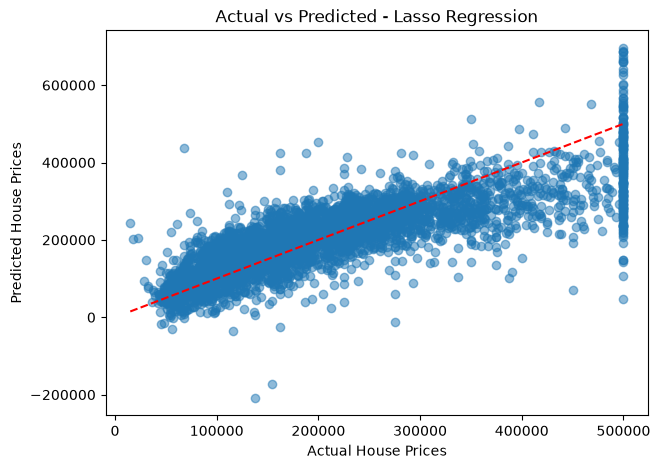

In [273]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_lasso_tuned, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Actual vs Predicted - Lasso Regression')

plt.show()

In [274]:
residuals_ridge = y_test - y_pred_ridge_tuned

residuals_lasso = y_test - y_pred_lasso_tuned

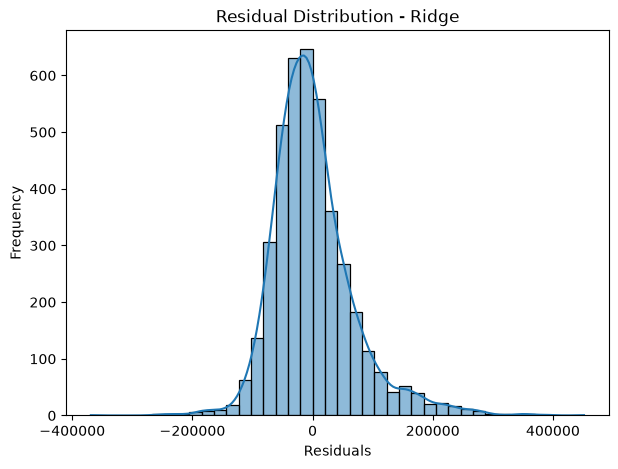

In [275]:
plt.figure(figsize=(7, 5))

sns.histplot(residuals_ridge, kde=True, bins=40)

plt.title('Residual Distribution - Ridge')
plt.xlabel('Residuals')
plt.ylabel('Frequency')

plt.show()

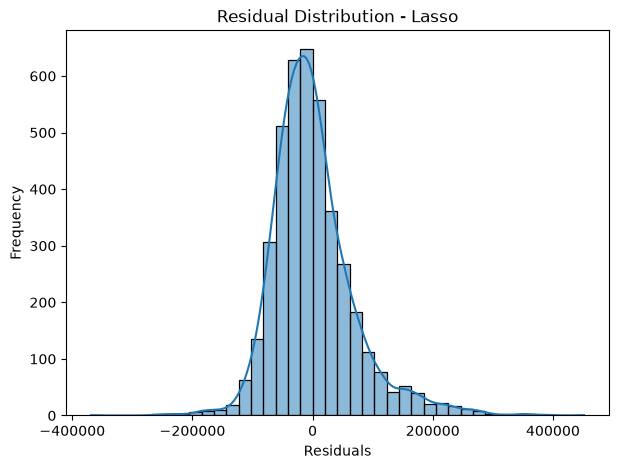

In [276]:
plt.figure(figsize=(7, 5))

sns.histplot(residuals_lasso, kde=True, bins=40)

plt.title('Residual Distribution - Lasso')
plt.xlabel('Residuals')
plt.ylabel('Frequency')

plt.show()

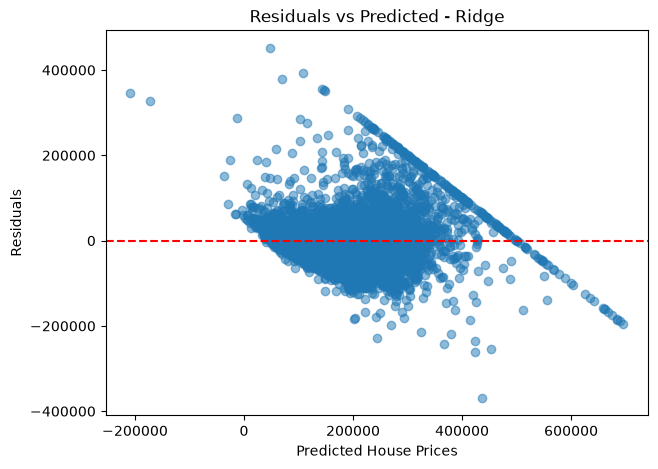

In [277]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_pred_ridge_tuned,
    residuals_ridge,
    alpha=0.5
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted House Prices')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted - Ridge')

plt.show()

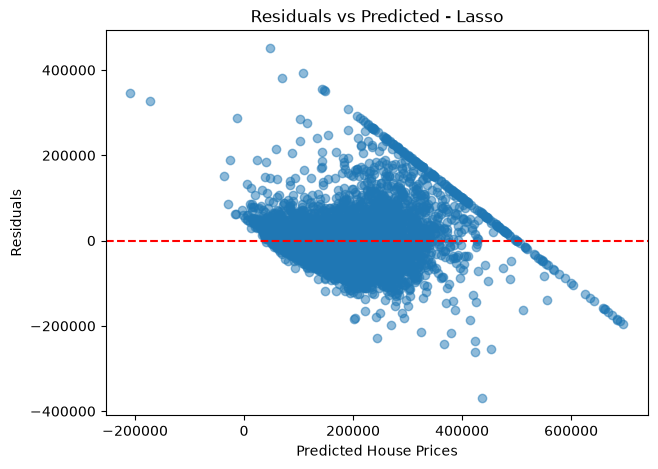

In [278]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_pred_lasso_tuned,
    residuals_lasso,
    alpha=0.5
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted House Prices')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted - Lasso')

plt.show()

In [279]:
final_results = pd.DataFrame({
    'Model': ['OLS', 'Tuned Ridge', 'Tuned Lasso'],
    'RMSE': [
        mean_squared_error(y_test, y_pred_ols) ** 0.5,
        mean_squared_error(y_test, y_pred_ridge_tuned) ** 0.5,
        mean_squared_error(y_test, y_pred_lasso_tuned) ** 0.5
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_ols),
        mean_absolute_error(y_test, y_pred_ridge_tuned),
        mean_absolute_error(y_test, y_pred_lasso_tuned)
    ],
    'R2 Score': [
        r2_score(y_test, y_pred_ols),
        r2_score(y_test, y_pred_ridge_tuned),
        r2_score(y_test, y_pred_lasso_tuned)
    ]
})

final_results

,Model,RMSE,MAE,R2 Score
0,OLS,68917.316732,49709.539532,0.637549
1,Tuned Ridge,68925.957248,49715.840814,0.637458
2,Tuned Lasso,68918.675805,49710.271515,0.637534


## CONCLUSION

I built a California Housing price prediction model using OLS, Ridge and Lasso regression. I performed EDA, imputed missing values (207 in total_bedrooms), engineered ratio and interaction features, checked multicollinearity using VIF, one-hot encoded ocean_proximity and standardized numerical features.

All three models performed almost identically (RMSE ≈ 68.9K, MAE ≈ 49.7K, R² ≈ 0.64). Hyperparameter tuning selected alpha = 1 for both Ridge and Lasso, so regularization did not meaningfully improve results. This suggests the limitation is the linear model itself, not overfitting. Future work: tree-based models and handling the capped house values.